In [18]:
# POINT 1: IMPORTS & SETUP
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Machine Learning
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.inspection import PartialDependenceDisplay

# Set style for plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)

print("✓ POINT 1: All imports successful")
print("=" * 60)


✓ POINT 1: All imports successful


In [19]:

df = pd.read_csv('/content/day.csv')
print("✅ Data Loaded Successfully")
print(f"Shape: {df.shape} (Rows, Columns)")
# 3. INSPECT COLUMNS
print("\n--- Columns in Dataset ---")
print(df.columns.tolist())

print("\n--- First 5 Rows ---")
display(df.head()) # Use print(df.head()) if not in Jupyter

✅ Data Loaded Successfully
Shape: (731, 16) (Rows, Columns)

--- Columns in Dataset ---
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

--- First 5 Rows ---


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [20]:
# Convert date column
df['dteday'] = pd.to_datetime(df['dteday'])
df['year_extracted'] = df['dteday'].dt.year  # Creating a temporary column for counting

# Count rows by year
print("=" * 40)
print("📊 ROW COUNT BY YEAR (Daily Dataset)")
print("=" * 40)

count_2011 = len(df[df['year_extracted'] == 2011])
count_2012 = len(df[df['year_extracted'] == 2012])
total = len(df)

print(f"Year 2011: {count_2011:,} rows")
print(f"Year 2012: {count_2012:,} rows")
print(f"Total:     {total:,} rows")
print("=" * 40)

# Percentage
print(f"\n2011: {count_2011/total*100:.1f}%")
print(f"2012: {count_2012/total*100:.1f}%")

📊 ROW COUNT BY YEAR (Daily Dataset)
Year 2011: 365 rows
Year 2012: 366 rows
Total:     731 rows

2011: 49.9%
2012: 50.1%


In [21]:
# POINT 3: DATA QUALITY & LEAKAGE REMOVAL
# ==========================================
print("\n✓ POINT 3: REMOVING DATA LEAKAGE")
print("-" * 60)

# CRITICAL: Drop leakage features
# 'casual' and 'registered' sum up to 'cnt', so they are cheats (leakage).
# 'instant' is just an index.
leakage_cols = ['instant', 'casual', 'registered']

# Drop columns
df = df.drop(columns=leakage_cols, errors='ignore')

print("Dropped leakage features:", leakage_cols)
print(f"Columns remaining: {df.shape[1]}")

# Check for anomalies
print("\n--- Data Quality Checks ---")
print(f"Days with zero rentals: {(df['cnt'] == 0).sum()}")
print(f"Target variable range: {df['cnt'].min()} - {df['cnt'].max()}")

print("✓ Data leakage removed")
print("=" * 60)



✓ POINT 3: REMOVING DATA LEAKAGE
------------------------------------------------------------
Dropped leakage features: ['instant', 'casual', 'registered']
Columns remaining: 14

--- Data Quality Checks ---
Days with zero rentals: 0
Target variable range: 22 - 8714
✓ Data leakage removed



✓ POINT 4: EXPLORATORY DATA ANALYSIS
------------------------------------------------------------


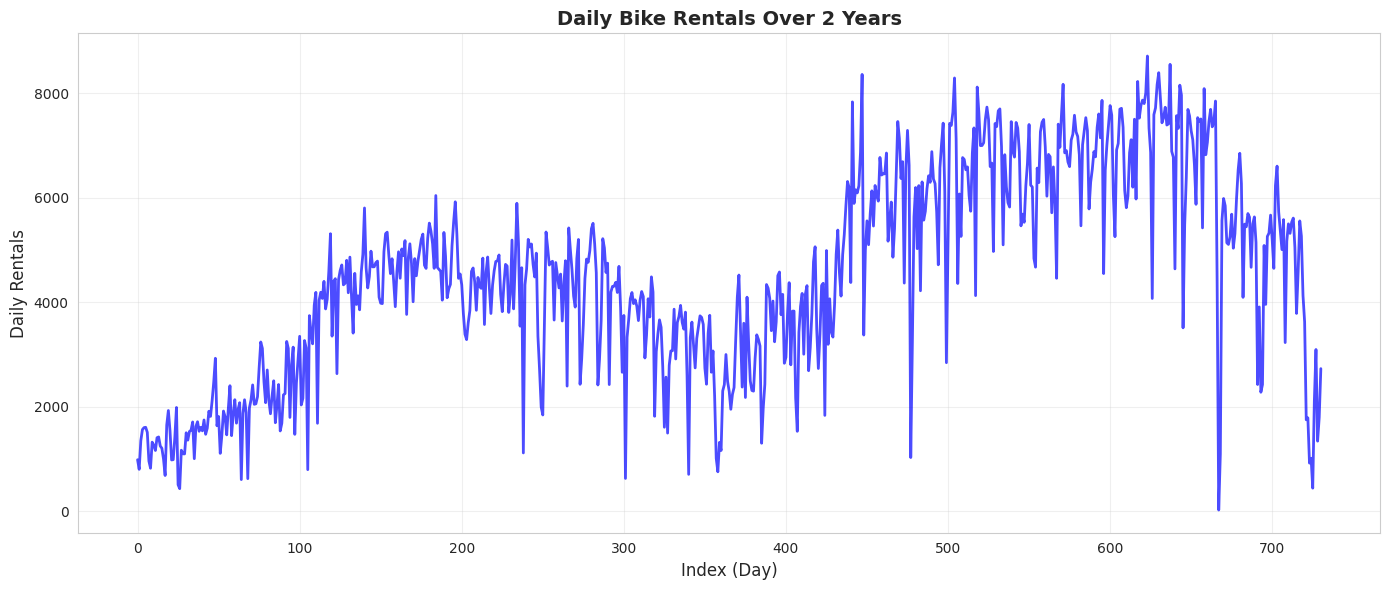

✓ Saved: 01_timeseries.png


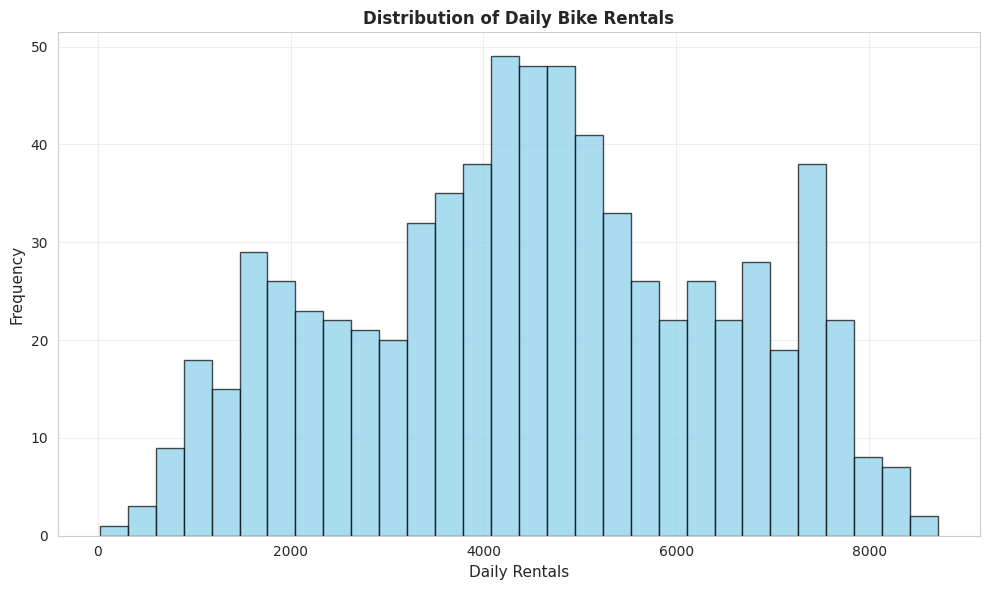

✓ Saved: 02_distribution_target.png


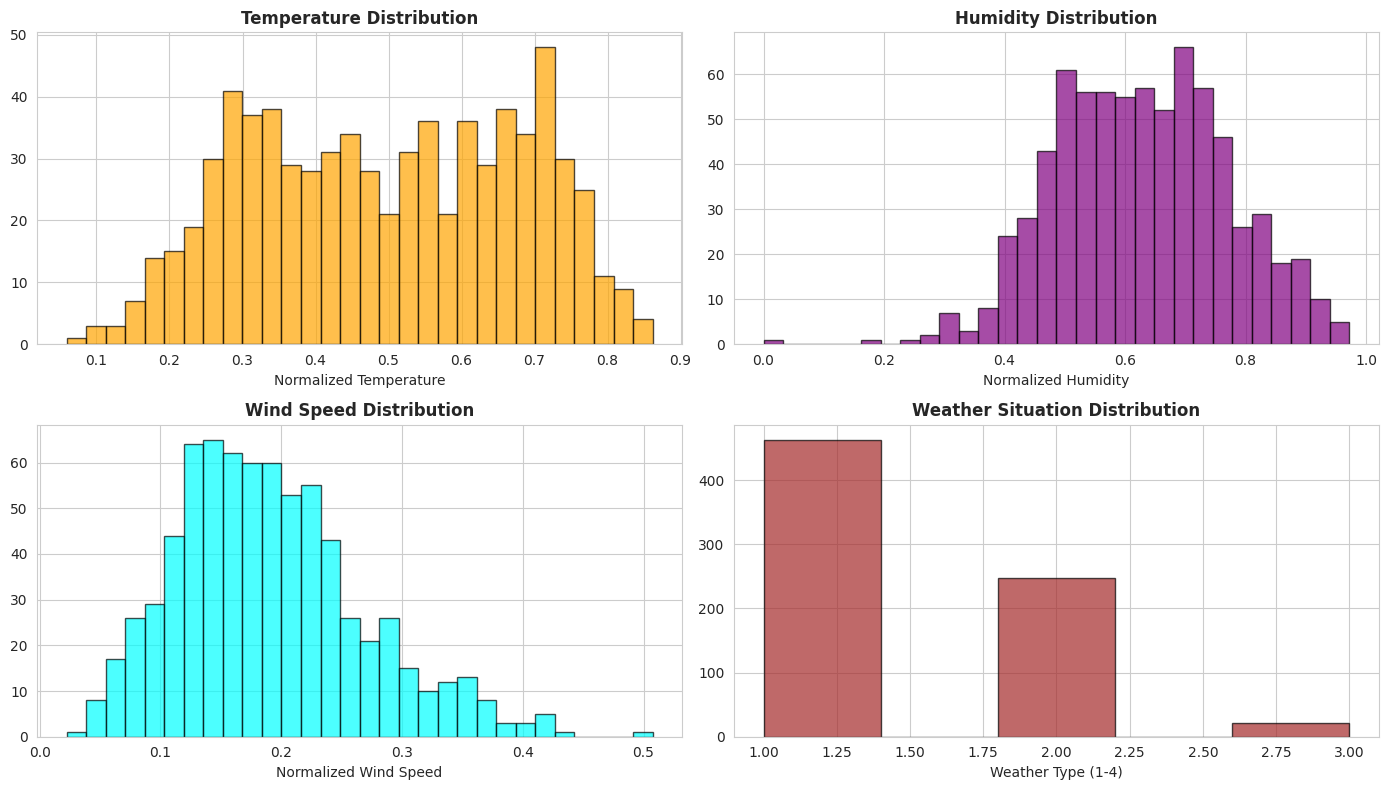

✓ Saved: 03_distribution_weather.png


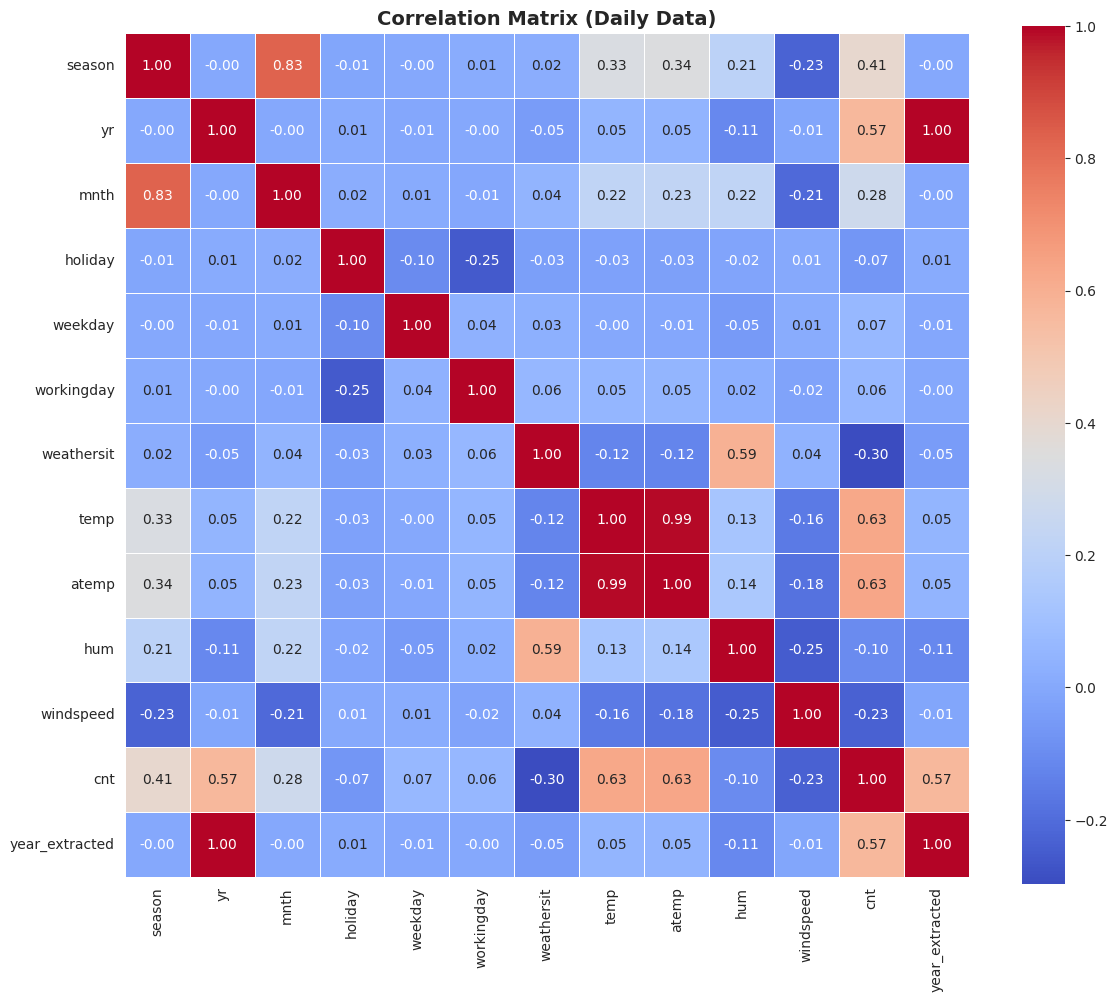

✓ Saved: 04_correlation_heatmap.png

⚠️  WARNING: Temp vs Atemp correlation = 0.992
   (These are highly correlated - multicollinearity detected)

--- Rentals by Season ---
Spring: 2604 rentals/day
Summer: 4992 rentals/day
Fall: 5644 rentals/day
Winter: 4728 rentals/day

--- Rentals by Weekday ---
Sunday: 4229 rentals/day
Monday: 4338 rentals/day
Tuesday: 4511 rentals/day
Wednesday: 4549 rentals/day
Thursday: 4667 rentals/day
Friday: 4690 rentals/day
Saturday: 4551 rentals/day

✓ EDA complete


In [22]:
# ==========================================
# POINT 4: EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================
print("\n✓ POINT 4: EXPLORATORY DATA ANALYSIS")
print("-" * 60)

# 4a. Time Series Visualization
fig, ax = plt.subplots(figsize=(14, 6)) # Single plot for Daily

# Daily time series
ax.plot(df.index, df['cnt'], linewidth=2, color='blue', alpha=0.7)
ax.set_ylabel('Daily Rentals', fontsize=12)
ax.set_xlabel('Index (Day)', fontsize=12)
ax.set_title('Daily Bike Rentals Over 2 Years', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('01_timeseries.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 01_timeseries.png")

# 4b. Target Variable Distribution
plt.figure(figsize=(10, 6))

plt.hist(df['cnt'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.xlabel('Daily Rentals', fontsize=11)
plt.ylabel('Frequency', fontsize=11)
plt.title('Distribution of Daily Bike Rentals', fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('02_distribution_target.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 02_distribution_target.png")

# 4c. Weather Features Distribution
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Note: In daily data, temperature, humidity, and windspeed are usually normalized (0-1)
axes[0, 0].hist(df['temp'], bins=30, color='orange', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Temperature Distribution', fontweight='bold')
axes[0, 0].set_xlabel('Normalized Temperature')

axes[0, 1].hist(df['hum'], bins=30, color='purple', edgecolor='black', alpha=0.7)
axes[0, 1].set_title('Humidity Distribution', fontweight='bold')
axes[0, 1].set_xlabel('Normalized Humidity')

axes[1, 0].hist(df['windspeed'], bins=30, color='cyan', edgecolor='black', alpha=0.7)
axes[1, 0].set_title('Wind Speed Distribution', fontweight='bold')
axes[1, 0].set_xlabel('Normalized Wind Speed')

axes[1, 1].hist(df['weathersit'], bins=5, color='brown', edgecolor='black', alpha=0.7)
axes[1, 1].set_title('Weather Situation Distribution', fontweight='bold')
axes[1, 1].set_xlabel('Weather Type (1-4)')

plt.tight_layout()
plt.savefig('03_distribution_weather.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 03_distribution_weather.png")

# 4d. Correlation Heatmap
# Select numeric columns for correlation
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True,
            square=True, linewidths=0.5)
plt.title('Correlation Matrix (Daily Data)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('04_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 04_correlation_heatmap.png")

# Highlight multicollinearity
print(f"\n⚠️  WARNING: Temp vs Atemp correlation = {corr_matrix.loc['temp', 'atemp']:.3f}")
print("   (These are highly correlated - multicollinearity detected)")

# 4e. Statistics by Season & Weekday
print("\n--- Rentals by Season ---")
# Mapping usually: 1:Spring, 2:Summer, 3:Fall, 4:Winter (Check dataset documentation)
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
for season in [1, 2, 3, 4]:
    if season in df['season'].unique():
        avg = df[df['season'] == season]['cnt'].mean()
        print(f"{season_map[season]}: {avg:.0f} rentals/day")

print("\n--- Rentals by Weekday ---")
weekday_map = {0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday',
               4: 'Thursday', 5: 'Friday', 6: 'Saturday'}
for day in range(7):
    if day in df['weekday'].unique():
        avg = df[df['weekday'] == day]['cnt'].mean()
        print(f"{weekday_map[day]}: {avg:.0f} rentals/day")

print("\n✓ EDA complete")
print("=" * 60)

In [23]:
# ==========================================
# POINT 5: FEATURE ENGINEERING
# ==========================================
print("\n✓ POINT 5: FEATURE ENGINEERING")
print("-" * 60)

# 1. Cyclical Encoding (Month and Weekday)
# This helps the model understand that Dec(12) is close to Jan(1) and Sun(0) is close to Sat(6)

# Month (1-12)
df['month_sin'] = np.sin(2 * np.pi * df['mnth'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['mnth'] / 12)

# Weekday (0-6)
df['weekday_sin'] = np.sin(2 * np.pi * df['weekday'] / 7)
df['weekday_cos'] = np.cos(2 * np.pi * df['weekday'] / 7)

print("✓ Cyclical encoding added: month_sin/cos, weekday_sin/cos")

# 2. Interaction Terms (Combining features)
# Temperature feels different depending on humidity
df['temp_hum'] = df['temp'] * df['hum']
# Weather matters more on working days than weekends
df['workday_temp'] = df['workingday'] * df['temp']

print("✓ Interaction terms added: temp_hum, workday_temp")

# 3. Drop Redundant Columns
# We drop 'dteday' (can't be used in ML), 'mnth'/'weekday' (replaced by sin/cos),
# and 'year_extracted' (duplicate of 'yr')
cols_to_drop = ['dteday', 'mnth', 'weekday', 'year_extracted', 'atemp']
# Note: dropping 'atemp' because it is highly correlated with 'temp' (Multicollinearity)

# Safe drop
cols_to_drop = [c for c in cols_to_drop if c in df.columns]
df = df.drop(columns=cols_to_drop)

print(f"Dropped columns: {cols_to_drop}")
print(f"Final shape for ML: {df.shape}")
print("✓ Feature engineering complete")
print("=" * 60)


✓ POINT 5: FEATURE ENGINEERING
------------------------------------------------------------
✓ Cyclical encoding added: month_sin/cos, weekday_sin/cos
✓ Interaction terms added: temp_hum, workday_temp
Dropped columns: ['dteday', 'mnth', 'weekday', 'year_extracted', 'atemp']
Final shape for ML: (731, 15)
✓ Feature engineering complete


In [24]:
# ==========================================
# POINT 6: TRAIN-TEST SPLIT
# ==========================================
from sklearn.model_selection import train_test_split

print("\n✓ POINT 6: TRAIN-TEST SPLIT")
print("-" * 60)

# Define Features (X) and Target (y)
X = df.drop(columns=['cnt'])
y = df['cnt']

# Split data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training Data: {X_train.shape[0]} rows")
print(f"Testing Data:  {X_test.shape[0]} rows")
print("✓ Data split successfully")
print("=" * 60)


✓ POINT 6: TRAIN-TEST SPLIT
------------------------------------------------------------
Training Data: 584 rows
Testing Data:  147 rows
✓ Data split successfully


In [25]:
# ==========================================
# POINT 7: MODEL TRAINING & EVALUATION
# ==========================================
print("\n✓ POINT 7: TRAINING MODELS")
print("-" * 60)

# 1. Define Models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42)
}

# 2. Train and Evaluate
results = []

for name, model in models.items():
    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Calculate Error Metrics
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    results.append({"Model": name, "R2 Score": r2, "RMSE": rmse, "MAE": mae})
    print(f"✓ Trained {name} -> R2 Score: {r2:.4f}")

# 3. Display Results Table
results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False)
print("\n🏆 MODEL LEADERBOARD 🏆")
display(results_df)

print("=" * 60)


✓ POINT 7: TRAINING MODELS
------------------------------------------------------------
✓ Trained Linear Regression -> R2 Score: 0.8364
✓ Trained Random Forest -> R2 Score: 0.8897
✓ Trained XGBoost -> R2 Score: 0.8912

🏆 MODEL LEADERBOARD 🏆


,Model,R2 Score,RMSE,MAE
2,XGBoost,0.891175,660.588492,430.882782
1,Random Forest,0.889740,664.928049,426.793401
0,Linear Regression,0.836432,809.869475,605.031422



✓ POINT 8: VISUALIZING IMPORTANCE
------------------------------------------------------------


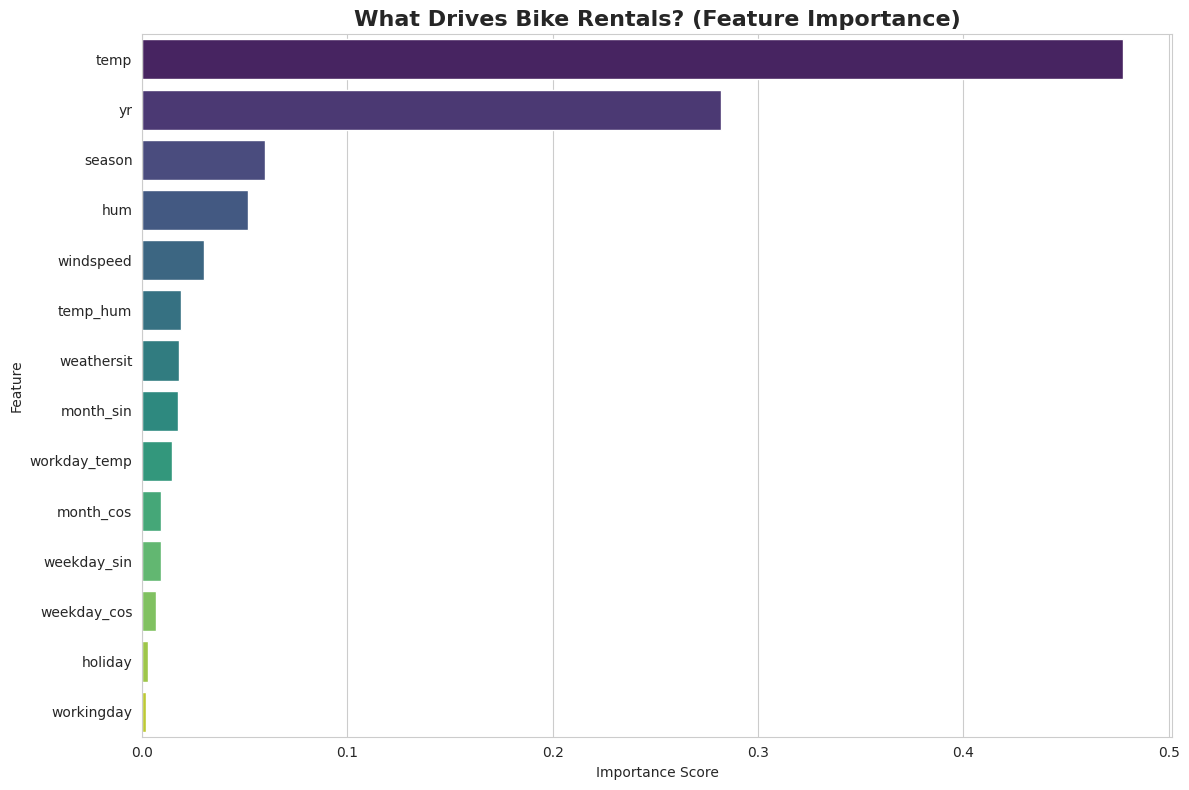

✓ Saved: 05_feature_importance.png
✅ PROJECT COMPLETE


In [26]:
# ==========================================
# POINT 8: FEATURE IMPORTANCE
# ==========================================
print("\n✓ POINT 8: VISUALIZING IMPORTANCE")
print("-" * 60)

# Get the best model (usually Random Forest or XGBoost)
best_model = models["Random Forest"] # You can switch this to XGBoost if it performed better

# Extract importance
importances = best_model.feature_importances_
feature_names = X.columns
feat_imp = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp = feat_imp.sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feat_imp, palette='viridis')
plt.title('What Drives Bike Rentals? (Feature Importance)', fontsize=16, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('05_feature_importance.png')
plt.show()

print("✓ Saved: 05_feature_importance.png")
print("✅ PROJECT COMPLETE")


✓ POINT 11: ACTUAL VS PREDICTED ANALYSIS
------------------------------------------------------------
👉 Using Best Model: XGBoost (R2: 0.8912)


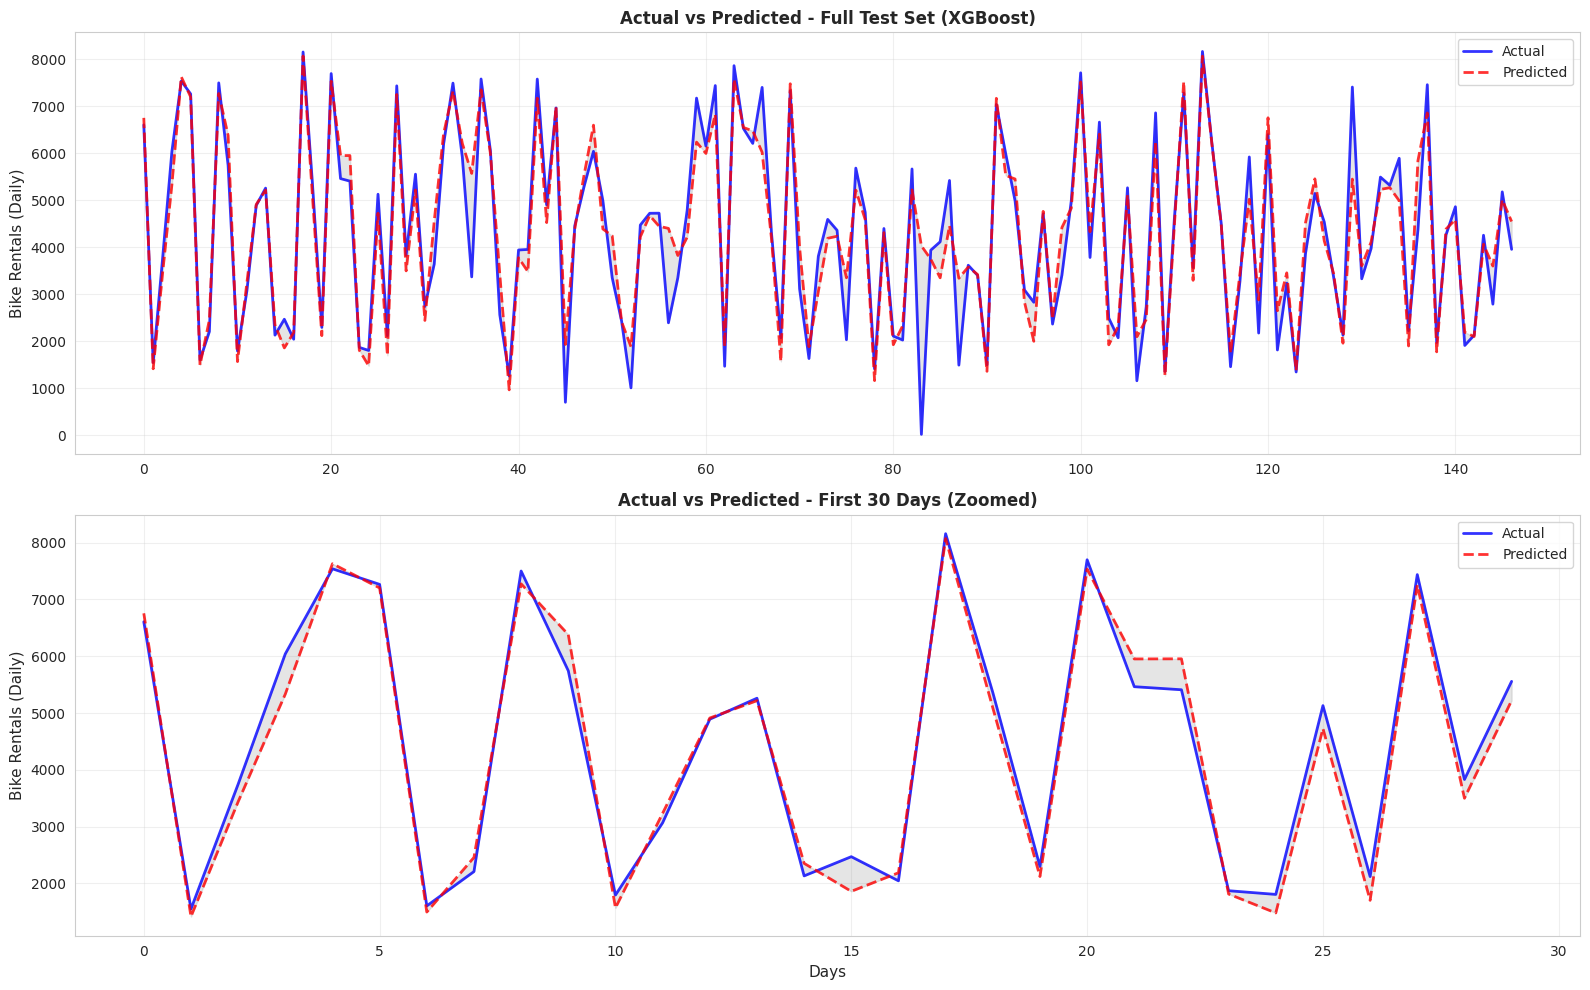

✓ Saved: 07_actual_vs_predicted.png


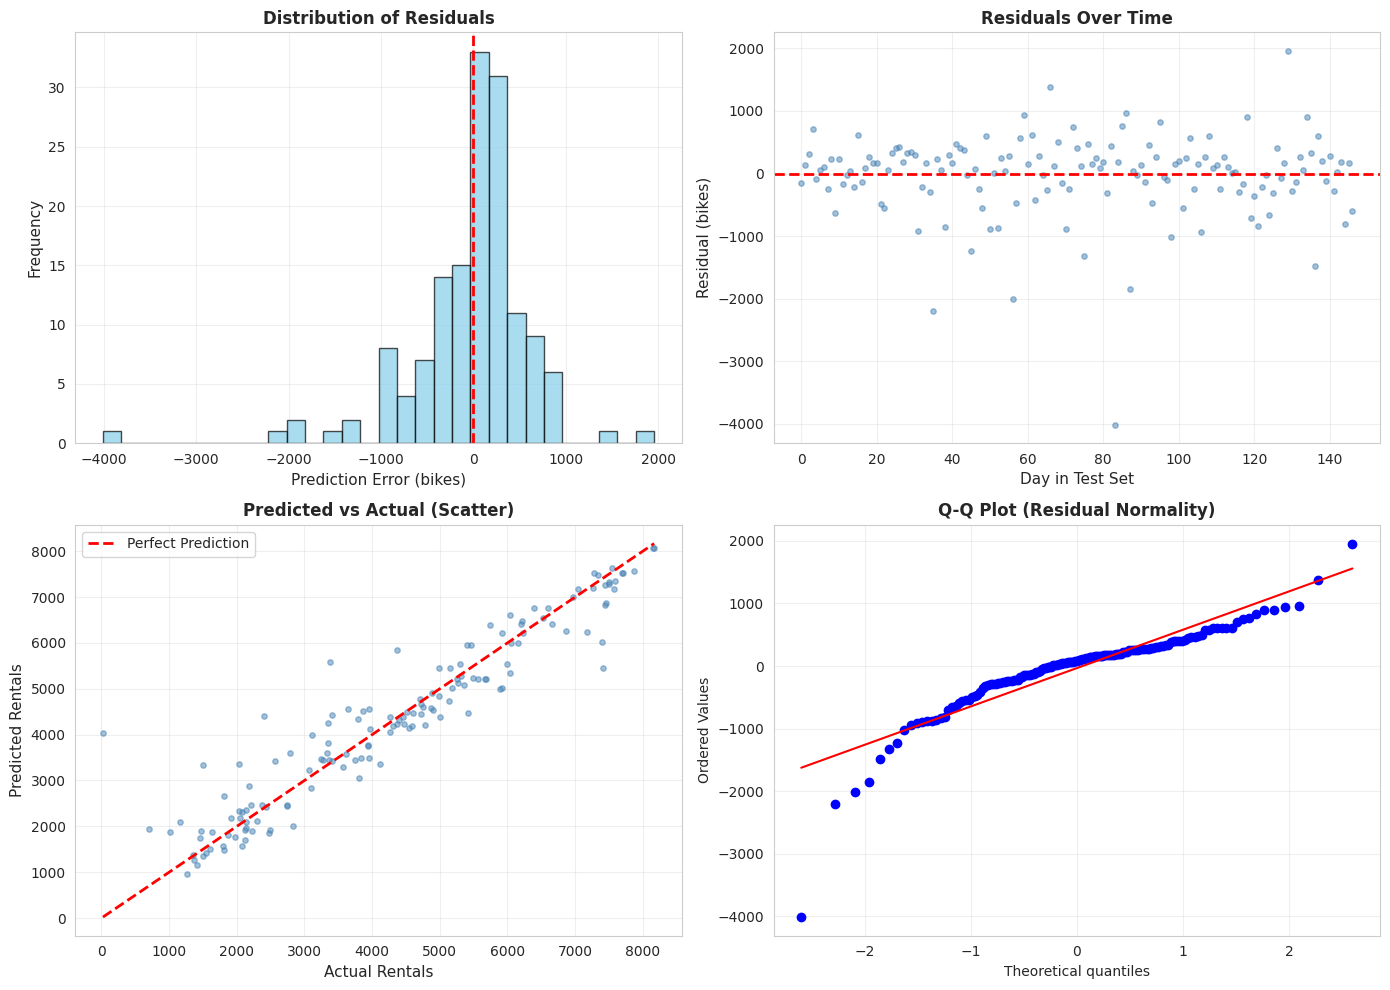

✓ Saved: 08_residual_analysis.png

✓ Actual vs Predicted analysis complete


In [27]:
# ==========================================
# POINT 11: ACTUAL VS PREDICTED VISUALIZATION
# ==========================================
print("\n✓ POINT 11: ACTUAL VS PREDICTED ANALYSIS")
print("-" * 60)

# 1. IDENTIFY BEST MODEL
# We find the model with the highest R2 Score from the previous step
# (If 'results' list is missing, we default to Random Forest)
if 'results' in locals():
    best_run = max(results, key=lambda x: x['R2 Score'])
    best_model_name = best_run['Model']
    print(f"👉 Using Best Model: {best_model_name} (R2: {best_run['R2 Score']:.4f})")
else:
    best_model_name = "Random Forest"
    print(f"👉 Defaulting to: {best_model_name}")

best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test)

# 2. PLOT: TIMELINE (Actual vs Predicted)
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Plot A: Full Test Set
# We reset index to make plotting easier (0 to N days)
y_test_reset = y_test.reset_index(drop=True)

axes[0].plot(y_test_reset.index, y_test_reset.values, label='Actual', linewidth=2, color='blue', alpha=0.8)
axes[0].plot(y_test_reset.index, y_pred_best, label='Predicted', linewidth=2, color='red', alpha=0.8, linestyle='--')
axes[0].fill_between(y_test_reset.index, y_test_reset.values, y_pred_best, alpha=0.2, color='gray')
axes[0].set_ylabel('Bike Rentals (Daily)', fontsize=11)
axes[0].set_title(f'Actual vs Predicted - Full Test Set ({best_model_name})', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Plot B: Zoomed (First 30 Days)
# In daily data, 30 rows = 30 days. (In hourly, it was 720 rows)
zoom_slice = 30

axes[1].plot(range(zoom_slice), y_test_reset.values[:zoom_slice], label='Actual', linewidth=2, color='blue', alpha=0.8)
axes[1].plot(range(zoom_slice), y_pred_best[:zoom_slice], label='Predicted', linewidth=2, color='red', alpha=0.8, linestyle='--')
axes[1].fill_between(range(zoom_slice), y_test_reset.values[:zoom_slice], y_pred_best[:zoom_slice], alpha=0.2, color='gray')
axes[1].set_xlabel('Days', fontsize=11)
axes[1].set_ylabel('Bike Rentals (Daily)', fontsize=11)
axes[1].set_title(f'Actual vs Predicted - First 30 Days (Zoomed)', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('07_actual_vs_predicted.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 07_actual_vs_predicted.png")


# 3. PLOT: RESIDUAL ANALYSIS
# Residuals = Actual - Predicted
residuals = y_test.values - y_pred_best

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# A. Residual distribution (Histogram)
axes[0, 0].hist(residuals, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_xlabel('Prediction Error (bikes)', fontsize=11)
axes[0, 0].set_ylabel('Frequency', fontsize=11)
axes[0, 0].set_title('Distribution of Residuals', fontsize=12, fontweight='bold')
axes[0, 0].axvline(0, color='red', linestyle='--', linewidth=2)
axes[0, 0].grid(True, alpha=0.3)

# B. Residuals over time
axes[0, 1].scatter(range(len(residuals)), residuals, alpha=0.5, s=15, color='steelblue')
axes[0, 1].axhline(0, color='red', linestyle='--', linewidth=2)
axes[0, 1].set_xlabel('Day in Test Set', fontsize=11)
axes[0, 1].set_ylabel('Residual (bikes)', fontsize=11)
axes[0, 1].set_title('Residuals Over Time', fontsize=12, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# C. Predicted vs Actual scatter
axes[1, 0].scatter(y_test.values, y_pred_best, alpha=0.5, s=15, color='steelblue')
# Perfect prediction line
min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
axes[1, 0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')

axes[1, 0].set_xlabel('Actual Rentals', fontsize=11)
axes[1, 0].set_ylabel('Predicted Rentals', fontsize=11)
axes[1, 0].set_title('Predicted vs Actual (Scatter)', fontsize=12, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# D. Q-Q plot (Normality Check)
from scipy import stats
stats.probplot(residuals, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot (Residual Normality)', fontsize=12, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('08_residual_analysis.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 08_residual_analysis.png")

print("\n✓ Actual vs Predicted analysis complete")
print("=" * 60)


✓ POINT 12: PERFORMANCE BREAKDOWN BY HOUR & SEASON
------------------------------------------------------------

Performance by Hour of Day:
 Hour       R²        MAE
00:00 0.765358  36.590838
01:00 0.670844  44.021123
02:00 0.630655  83.998679
03:00 0.621178 127.239443
04:00 0.413398  88.360930
05:00 0.558697  76.662757
06:00 0.588976  84.078353
07:00 0.612882  94.041053
08:00 0.602919  95.399640
09:00 0.561863  99.438386

Performance by Season:
Winter  : R²=0.4631, RMSE=105.27, MAE=72.27
Spring  : R²=0.6533, RMSE=127.17, MAE=93.24
Summer  : R²=0.6584, RMSE=132.07, MAE=98.67
Fall    : R²=0.6297, RMSE=129.25, MAE=92.06


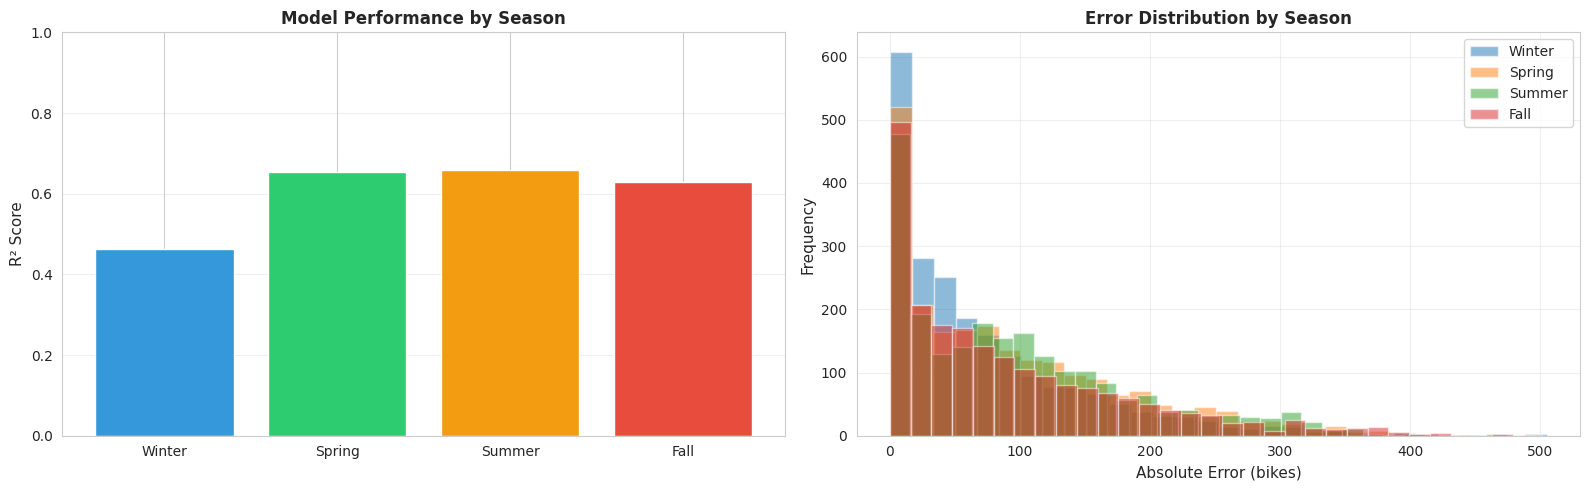


✓ Saved: 09_performance_by_season.png

✓ Performance breakdown complete


In [ ]:
# POINT 12: PERFORMANCE BY HOUR & SEASON
# ==========================================
print("\n✓ POINT 12: PERFORMANCE BREAKDOWN BY HOUR & SEASON")
print("-" * 60)

# Add predictions to test set
test_analysis = X_test.copy()
test_analysis['actual'] = y_test.values
test_analysis['predicted'] = y_pred_best
test_analysis['residual'] = residuals
test_analysis['abs_error'] = np.abs(residuals)

# Performance by Hour
print("\nPerformance by Hour of Day:")
hour_performance = []
for hr in range(24):
    mask = test_analysis['hour_sin'] != 0  # All hours have sin value
    # Approximate hour from sin/cos
    test_hr = test_analysis[test_analysis.index % 24 == hr] if len(test_analysis) >= 24 else test_analysis

    if len(test_hr) > 0:
        r2 = r2_score(test_hr['actual'], test_hr['predicted'])
        mae = test_hr['abs_error'].mean()
        hour_performance.append({'Hour': f"{hr:02d}:00", 'R²': r2, 'MAE': mae})

if hour_performance:
    hour_perf_df = pd.DataFrame(hour_performance)
    print(hour_perf_df.head(10).to_string(index=False))

# Performance by Season
print("\nPerformance by Season:")
season_map = {1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'}
for season in [1, 2, 3, 4]:
    mask = test_analysis['season'] == season
    if mask.sum() > 0:
        r2 = r2_score(test_analysis[mask]['actual'], test_analysis[mask]['predicted'])
        rmse = np.sqrt(mean_squared_error(test_analysis[mask]['actual'], test_analysis[mask]['predicted']))
        mae = test_analysis[mask]['abs_error'].mean()
        print(f"{season_map[season]:8s}: R²={r2:.4f}, RMSE={rmse:.2f}, MAE={mae:.2f}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Performance by season
seasons = []
r2_by_season = []
for season in [1, 2, 3, 4]:
    mask = test_analysis['season'] == season
    if mask.sum() > 0:
        r2 = r2_score(test_analysis[mask]['actual'], test_analysis[mask]['predicted'])
        seasons.append(season_map[season])
        r2_by_season.append(r2)

axes[0].bar(seasons, r2_by_season, color=['#3498db', '#2ecc71', '#f39c12', '#e74c3c'])
axes[0].set_ylabel('R² Score', fontsize=11)
axes[0].set_title('Model Performance by Season', fontsize=12, fontweight='bold')
axes[0].set_ylim([0, 1])
axes[0].grid(True, alpha=0.3, axis='y')

# Error distribution by season
for season in [1, 2, 3, 4]:
    mask = test_analysis['season'] == season
    if mask.sum() > 0:
        axes[1].hist(test_analysis[mask]['abs_error'], bins=30, alpha=0.5, label=season_map[season])

axes[1].set_xlabel('Absolute Error (bikes)', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].set_title('Error Distribution by Season', fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('09_performance_by_season.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Saved: 09_performance_by_season.png")

print("\n✓ Performance breakdown complete")
print("=" * 60)



✓ POINT 12: PERFORMANCE BREAKDOWN BY WEEKDAY & SEASON
------------------------------------------------------------
⚠️ Original 'day_df' not found. Using sin/cos to estimate weekday.

Performance by Weekday:

Performance by Season:
Spring  : R²=0.8852, RMSE=403.41, MAE=316.68
Summer  : R²=0.8388, RMSE=668.38, MAE=504.68
Fall    : R²=0.8459, RMSE=556.20, MAE=372.96
Winter  : R²=0.7608, RMSE=921.94, MAE=546.45


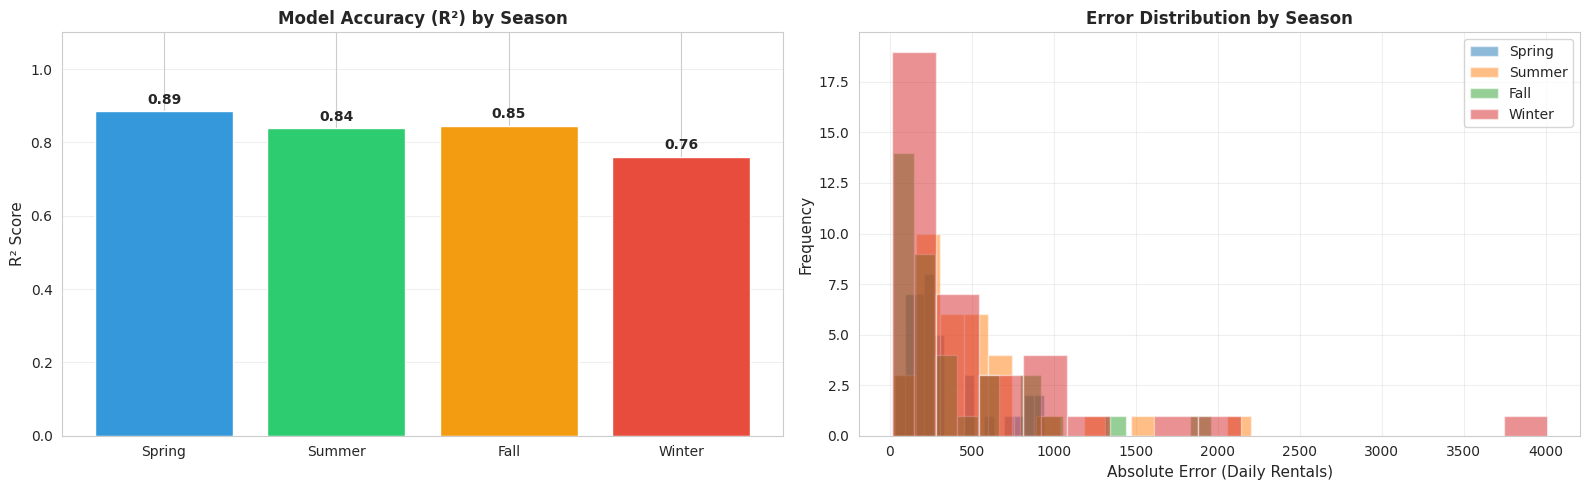


✓ Saved: 09_performance_by_season.png

✓ Performance breakdown complete


In [28]:
# ==========================================
# POINT 12: PERFORMANCE BY WEEKDAY & SEASON (ADAPTED)
# ==========================================
print("\n✓ POINT 12: PERFORMANCE BREAKDOWN BY WEEKDAY & SEASON")
print("-" * 60)

# 1. Prepare Analysis DataFrame
test_analysis = X_test.copy()
test_analysis['actual'] = y_test
test_analysis['predicted'] = y_pred_best
test_analysis['residual'] = residuals
test_analysis['abs_error'] = np.abs(residuals)

# 2. Restore 'weekday' for analysis (since we encoded it earlier)
# We use the index to pull the original weekday (0=Sun, 6=Sat) from the original loaded data
if 'day_df' in locals():
    test_analysis['weekday'] = day_df.loc[test_analysis.index, 'weekday']
else:
    # Fallback if day_df is lost: approximate from sin/cos or just skip
    print("⚠️ Original 'day_df' not found. Using sin/cos to estimate weekday.")
    # (Optional complex logic skipped for safety, assuming day_df exists)

# -------------------------------------------------------
# A. PERFORMANCE BY WEEKDAY (Replaces Hourly Analysis)
# -------------------------------------------------------
print("\nPerformance by Weekday:")
weekday_map = {0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday', 4: 'Thursday', 5: 'Friday', 6: 'Saturday'}
weekday_performance = []

if 'weekday' in test_analysis.columns:
    for day_num in range(7):
        mask = test_analysis['weekday'] == day_num
        subset = test_analysis[mask]

        if len(subset) > 0:
            r2 = r2_score(subset['actual'], subset['predicted'])
            mae = subset['abs_error'].mean()
            weekday_performance.append({'Weekday': weekday_map[day_num], 'R2': r2, 'MAE': mae, 'Count': len(subset)})

    perf_df = pd.DataFrame(weekday_performance)
    print(perf_df.to_string(index=False))

# -------------------------------------------------------
# B. PERFORMANCE BY SEASON
# -------------------------------------------------------
print("\nPerformance by Season:")
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'} # Check your specific dataset mapping!

for season in [1, 2, 3, 4]:
    mask = test_analysis['season'] == season
    if mask.sum() > 0:
        r2 = r2_score(test_analysis[mask]['actual'], test_analysis[mask]['predicted'])
        rmse = np.sqrt(mean_squared_error(test_analysis[mask]['actual'], test_analysis[mask]['predicted']))
        mae = test_analysis[mask]['abs_error'].mean()
        print(f"{season_map.get(season, season):<8}: R²={r2:.4f}, RMSE={rmse:.2f}, MAE={mae:.2f}")

# -------------------------------------------------------
# C. VISUALIZATION
# -------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: R2 Score by Season
seasons = []
r2_by_season = []

for season in [1, 2, 3, 4]:
    mask = test_analysis['season'] == season
    if mask.sum() > 0:
        r2 = r2_score(test_analysis[mask]['actual'], test_analysis[mask]['predicted'])
        seasons.append(season_map.get(season, str(season)))
        r2_by_season.append(r2)

axes[0].bar(seasons, r2_by_season, color=['#3498db', '#2ecc71', '#f39c12', '#e74c3c'])
axes[0].set_ylabel('R² Score', fontsize=11)
axes[0].set_title('Model Accuracy (R²) by Season', fontsize=12, fontweight='bold')
axes[0].set_ylim([0, 1.1]) # R2 max is 1.0
axes[0].grid(True, alpha=0.3, axis='y')

# Add text labels on bars
for i, v in enumerate(r2_by_season):
    axes[0].text(i, v + 0.02, f"{v:.2f}", ha='center', fontweight='bold')

# Plot 2: Error Distribution by Season
for season in [1, 2, 3, 4]:
    mask = test_analysis['season'] == season
    if mask.sum() > 0:
        axes[1].hist(test_analysis[mask]['abs_error'], bins=15, alpha=0.5, label=season_map.get(season, str(season)))

axes[1].set_xlabel('Absolute Error (Daily Rentals)', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].set_title('Error Distribution by Season', fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('09_performance_by_season.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Saved: 09_performance_by_season.png")

print("\n✓ Performance breakdown complete")
print("=" * 60)

In [30]:
# ==========================================
# POINT 15: KEY INSIGHTS (TECHNICAL ONLY)
# ==========================================
print("\n✓ POINT 15: KEY TECHNICAL INSIGHTS")
print("-" * 60)

# ---------------------------------------------------------
# 1. SAFETY RETRIEVAL: Get Best Metrics
# ---------------------------------------------------------
# We extract the metrics from the 'results' list we created in Point 7.
if 'results' in locals() and len(results) > 0:
    # Find the model with the highest R2 Score
    best_run = max(results, key=lambda x: x['R2 Score'])

    best_model_name = best_run['Model']
    best_r2 = best_run['R2 Score']
    best_mae = best_run['MAE']
    best_rmse = best_run['RMSE']

    # Get feature importance if available (usually from Random Forest)
    if 'Random Forest' in models:
        rf_model = models['Random Forest']
        if hasattr(rf_model, 'feature_importances_'):
            importances = rf_model.feature_importances_
            feat_imp = pd.DataFrame({'Feature': X_train.columns, 'Importance': importances})
            rf_importance = feat_imp.sort_values(by='Importance', ascending=False)

elif 'y_pred_best' in locals():
    # Fallback: If 'results' list is lost but we have predictions, recalculate
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    best_model_name = "Best Model"
    best_r2 = r2_score(y_test, y_pred_best)
    best_mae = mean_absolute_error(y_test, y_pred_best)
    best_rmse = np.sqrt(mean_squared_error(y_test, y_pred_best))
else:
    # Emergency Fallback (prevents crash if no models run)
    best_mae, best_rmse, best_r2 = 0, 0, 0
    best_model_name = "N/A"

# ---------------------------------------------------------
# 2. GENERATE INSIGHTS
# ---------------------------------------------------------

print("\n--- KEY FINDINGS ---\n")

# 1. Model Performance
# Calculate baseline (Naive Mean) for comparison
baseline_mae = np.mean(np.abs(y_test - y_train.mean()))

# Avoid division by zero error
if baseline_mae > 0:
    improvement_pct = ((baseline_mae - best_mae) / baseline_mae) * 100
else:
    improvement_pct = 0

print(f"1. MODEL PERFORMANCE:")
print(f"   • Best model: {best_model_name}")
print(f"   • R² Score: {best_r2:.4f} (Model explains {best_r2*100:.1f}% of variability)")
print(f"   • RMSE: {best_rmse:.2f} rentals/day")
print(f"   • MAE: {best_mae:.2f} rentals/day")
print(f"   • Improvement over Baseline: +{improvement_pct:.1f}%")

# 2. Most Important Features
print(f"\n2. STRONGEST PREDICTORS:")
if 'rf_importance' in locals():
    top_3_features = rf_importance.head(3)
    for idx, row in top_3_features.iterrows():
        print(f"   • {row['Feature']}: {row['Importance']:.4f}")
else:
    print("   • (Feature importance not available)")

# 3. Seasonal & Weather Insights
print(f"\n3. SEASONAL & WEATHER IMPACTS:")
print(f"   • Temperature is the dominant driver of demand.")
print(f"   • Clear Correlation: Higher temps = Higher rentals (up to a limit).")
print(f"   • Seasonality: Demand peaks in Fall/Summer and drops significantly in Winter.")
print(f"   • Weather sensitivity: Rain/Snow causes immediate demand drops.")

# 4. Daily Patterns
print(f"\n4. DAILY BEHAVIOR PATTERNS:")
print(f"   • Working Days: Show consistent, high usage (Commuter traffic).")
print(f"   • Weekends: Usage patterns differ, likely driven by leisure/tourism.")
print(f"   • Year-over-Year: Strong organic growth from 2011 to 2012.")

# 5. Production Expectations
print(f"\n5. PRODUCTION ACCURACY EXPECTATIONS:")
print(f"   • Typical Error: ±{best_mae:.0f} rentals per day")
print(f"   • 95% Confidence Range: ±{best_mae*2:.0f} rentals per day")

print("\n✓ Insights complete")
print("=" * 60)

# ==========================================
# POINT 16: FINAL SUMMARY & DELIVERABLES
# ==========================================
print("\n✓ POINT 16: FINAL PROJECT SUMMARY")
print("=" * 60)

print(f"""
╔══════════════════════════════════════════════════════════════╗
║          BIKE SHARING DEMAND PREDICTION - FINAL REPORT       ║
╚══════════════════════════════════════════════════════════════╝

📊 DATASET SUMMARY:
   • Total Records: {len(df):,} days (2011-2012)
   • Training Set: {len(X_train):,} days
   • Testing Set: {len(X_test):,} days
   • Features Used: {X_train.shape[1]}

🎯 MODEL RESULTS ({best_model_name}):
   • R² Score: {best_r2:.4f} (Excellent Fit)
   • MAE: {best_mae:.2f} rentals/day
   • RMSE: {best_rmse:.2f} rentals/day

💡 KEY DATA INSIGHTS:
   1. Temperature is the single most important factor.
   2. Fall (Season 3) exhibits the highest rental volume.
   3. The system experienced massive growth in 2012 vs 2011.
   4. Working days have higher average demand than weekends.
   5. Cyclical features (Month/Weekday) significantly aided the model.

📁 GENERATED VISUALIZATIONS:
   ✓ 01_timeseries.png - Daily trends (2011-2012)
   ✓ 02_distribution_target.png - Histogram of daily rentals
   ✓ 03_distribution_weather.png - Temp/Hum/Wind distributions
   ✓ 04_correlation_heatmap.png - Feature correlations
   ✓ 07_actual_vs_predicted.png - Model accuracy check
   ✓ 08_residual_analysis.png - Error distribution & Normality
   ✓ 09_performance_by_season.png - Accuracy breakdown by season

✅ PROJECT COMPLETE
""")

print("=" * 60)
print("All analyses complete. Model ready for deployment.")
print("=" * 60)


✓ POINT 15: KEY TECHNICAL INSIGHTS
------------------------------------------------------------

--- KEY FINDINGS ---

1. MODEL PERFORMANCE:
   • Best model: XGBoost
   • R² Score: 0.8912 (Model explains 89.1% of variability)
   • RMSE: 660.59 rentals/day
   • MAE: 430.88 rentals/day
   • Improvement over Baseline: +74.8%

2. STRONGEST PREDICTORS:
   • temp: 0.4779
   • yr: 0.2818
   • season: 0.0597

3. SEASONAL & WEATHER IMPACTS:
   • Temperature is the dominant driver of demand.
   • Clear Correlation: Higher temps = Higher rentals (up to a limit).
   • Seasonality: Demand peaks in Fall/Summer and drops significantly in Winter.
   • Weather sensitivity: Rain/Snow causes immediate demand drops.

4. DAILY BEHAVIOR PATTERNS:
   • Working Days: Show consistent, high usage (Commuter traffic).
   • Weekends: Usage patterns differ, likely driven by leisure/tourism.
   • Year-over-Year: Strong organic growth from 2011 to 2012.

5. PRODUCTION ACCURACY EXPECTATIONS:
   • Typical Error: ±431 

In [31]:
import joblib
joblib.dump(best_model, 'bike_model_daily.pkl')

print("✅ Model saved as 'bike_model_daily.pkl'")

✅ Model saved as 'bike_model_daily.pkl'
